<a href="https://colab.research.google.com/github/DrDourado/ME_640_Optimum_Design_Fall_2026/blob/main/ME640_04_DOE_Surrogate_Design.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# ME 640 – Optimum Design Methods
## Practical Design of Experiments, Latin Hypercube Sampling, Surrogate Modeling, and Surrogate-Based Design

### Learning objectives
By the end of this notebook, students should be able to:

1. Explain why **Design of Experiments (DOE)** is important in engineering design.
2. Distinguish between **full factorial**, **fractional/alternative**, and **space-filling** designs.
3. Construct and visualize a **Latin Hypercube Sample (LHS)**.
4. Explain why surrogate models are useful when experiments or simulations are expensive.
5. Fit and assess several common surrogate models.
6. Distinguish **interpolation**, **prediction**, and **optimization**.
7. Formulate and solve a **surrogate-based design optimization** problem.
8. Recognize important practical issues: scaling, replication, noise, validation, extrapolation, and sequential enrichment.

> **Course context.** The reference lecture motivates DOE as a statistics-based way to obtain predictive knowledge of a multivariable process with relatively few trials, contrasts this with expensive full-factorial experimentation, introduces Latin Hypercube designs, and concludes with a paper-helicopter optimization case study. This notebook expands those ideas into a computational workflow suitable for optimum design.


In [ ]:
# Core packages used throughout the lecture
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import qmc
from scipy.optimize import differential_evolution
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict

np.random.seed(42)



# 1. Why experiment design matters in optimum design

Engineering design usually asks a question such as


$$
\min_{\mathbf{x}} f(\mathbf{x})
\quad\text{or}\quad
\max_{\mathbf{x}} f(\mathbf{x})
$$

subject to

$$
g_j(\mathbf{x})\le 0,\qquad
\mathbf{x}^{L}\le\mathbf{x}\le\mathbf{x}^{U}.
$$

The difficulty is that the objective $f(\mathbf{x})$ may not be available as a simple equation. A single evaluation may require:

- a physical experiment,
- a CFD or finite-element simulation,
- a prototype,
- a wind-tunnel test,
- a fatigue test,
- or another expensive numerical/experimental process.

If evaluations are expensive, we cannot simply ask an optimizer to evaluate thousands of arbitrary designs. We first need to decide **where to collect information**. That is the role of DOE.

### DOE as optimization of the information-gathering process

A useful engineering interpretation is:

> DOE chooses a limited set of input combinations so that the resulting observations provide as much useful information as possible about the design space.

DOE can help answer:

- Which factors have the largest effect on the response?
- How does the response vary as factors change?
- Are there interactions among factors?
- Is the response nonlinear?
- Where are promising design regions?
- What factor levels are likely to produce a desirable response?

This is especially important when DOE is used as the front end of **surrogate-based optimization**.



# 2. Basic DOE terminology

Suppose an experiment has $d$ controllable variables.

| Term | Meaning |
|---|---|
| **Factor / design variable** | Input intentionally changed by the designer |
| **Level** | A selected value of a factor |
| **Response** | Measured or simulated output |
| **Run / trial** | One tested combination of factor levels |
| **Replication** | Repeating the same design to estimate random variation |
| **Interaction** | Effect of one factor depends on another factor |
| **Design space** | Region containing all allowable input combinations |
| **Experimental design** | Selected set of points at which the response is evaluated |

A common coded representation maps physical variables into approximately $[-1,1]$:

$
z_i = 2\frac{x_i-x_i^L}{x_i^U-x_i^L}-1.
$

Coding is useful because variables with different physical units then occupy comparable numerical ranges.



# 3. Full factorial designs

A **full factorial design** evaluates every combination of the selected levels of every factor.

If factor $i$ has $L_i$ levels, the number of experiments is

$
N=\prod_{i=1}^{d}L_i.
$

If all $d$ factors have $L$ levels,

$
N=L^d.
$

### Example from the reference lecture

Consider tire wear as a function of:

- speed: 55 or 70 mph,
- tire pressure: 27 or 32 psi,
- vehicle model: A or B.

There are three factors with two levels each:

$
N=2^3=8.
$

This is manageable and permits all combinations to be observed.


In [ ]:
# Generate the 2^3 coded full-factorial design
import itertools

factorial = pd.DataFrame(
    list(itertools.product([-1, 1], repeat=3)),
    columns=["Speed", "Pressure", "Car model"]
)
factorial.index = np.arange(1, len(factorial)+1)
factorial


,Speed,Pressure,Car model
1,-1,-1,-1
2,-1,-1,1
3,-1,1,-1
4,-1,1,1
5,1,-1,-1
6,1,-1,1
7,1,1,-1
8,1,1,1



## Advantages and limitations of factorial designs

### Advantages
- systematic and easy to interpret;
- good for estimating main effects and interactions;
- no arbitrary gaps among combinations at the chosen levels;
- highly useful when the number of factors is small.

### Limitation: combinatorial growth

The number of experiments grows exponentially with the number of factors. The reference lecture gives an aerospace example with **14 factors** and at least **3 levels per factor** to represent possible nonlinearities.

$
N=3^{14}.
$


In [ ]:
N = 3**14
print(f"3^14 = {N:,} experiments")


3^14 = 4,782,969 experiments



This illustrates the **curse of dimensionality** in experimental design. Even before optimization begins, exhaustive sampling may be impossible.

For expensive engineering evaluations, the objective therefore changes from:

> “Test every combination”

to:

> “Select a limited number of informative combinations that cover the relevant design space.”



# 4. Alternative experimental designs

Different experimental objectives call for different designs.

### Factorial and fractional factorial designs
Best suited to estimating factor effects and interactions when factors are naturally represented at discrete levels. Fractional factorial designs intentionally evaluate only a subset of combinations, accepting some confounding to reduce cost.

### Response Surface Methodology (RSM) designs
Designs such as **central composite** and **Box–Behnken** designs are often paired with low-order polynomial response surfaces. They are useful for local curvature and classical response-surface optimization.

### Space-filling designs
When the goal is to construct a global surrogate over a continuous multidimensional region, we often want points distributed broadly throughout the domain rather than concentrated at corners or a few prescribed levels.

Examples include:

- random sampling,
- Latin Hypercube Sampling,
- maximin designs,
- low-discrepancy sequences such as Sobol sequences.

This lecture emphasizes **Latin Hypercube Sampling (LHS)** because it is simple, efficient, and widely used in computer experiments and engineering surrogate modeling.



# 5. Latin Hypercube Sampling (LHS)

## 5.1 Core idea

For $N$ samples, LHS divides the range of **each input variable** into $N$ equally probable intervals and samples each interval exactly once.

For two variables and $N=10$:

- the $x_1$ axis is divided into 10 strata;
- the $x_2$ axis is divided into 10 strata;
- exactly one point appears in every stratum of $x_1$;
- exactly one point appears in every stratum of $x_2$.

The strata are then paired using permutations.

This does **not** mean that every two-dimensional grid cell is sampled. Instead, LHS guarantees one-dimensional stratification for every variable.


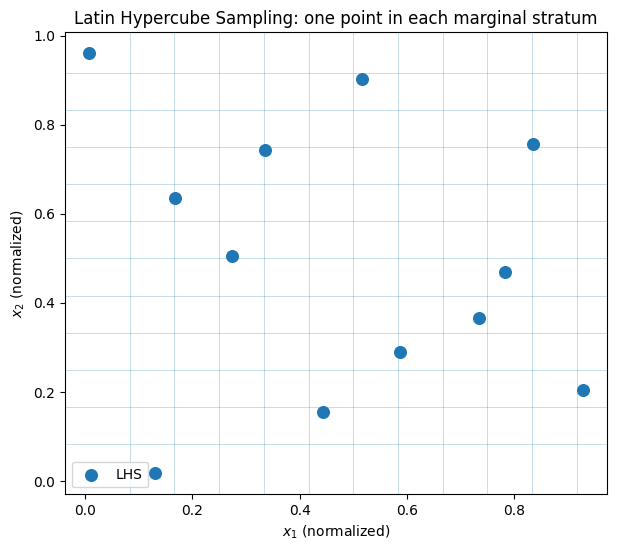

In [ ]:
# Compare ordinary random sampling and LHS in two dimensions
N = 12
rng = np.random.default_rng(4)

X_random = rng.random((N, 2))
sampler = qmc.LatinHypercube(d=2, seed=4)
X_lhs = sampler.random(N)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(X_lhs[:,0], X_lhs[:,1], s=70, label="LHS")
for k in range(1, N):
    ax.axvline(k/N, linewidth=0.5, alpha=0.35)
    ax.axhline(k/N, linewidth=0.5, alpha=0.35)
ax.set(xlabel="$x_1$ (normalized)", ylabel="$x_2$ (normalized)",
       title="Latin Hypercube Sampling: one point in each marginal stratum")
ax.legend()
plt.show()



## 5.2 Scaling an LHS to physical variables

LHS is conveniently generated in the unit hypercube,

$
0\le u_i\le 1.
$

For physical bounds $x_i^L,x_i^U$,

$
x_i=x_i^L+u_i(x_i^U-x_i^L).
$

This makes LHS convenient for engineering variables with different units.


In [ ]:
# Example: scale an LHS to two physical design variables
bounds = np.array([[0.5, 2.0],     # thickness [mm]
                   [20.0, 80.0]])  # angle [deg]

sample = qmc.LatinHypercube(d=2, seed=7).random(10)
X_phys = qmc.scale(sample, bounds[:,0], bounds[:,1])

pd.DataFrame(X_phys, columns=["Thickness [mm]", "Angle [deg]"]).round(3)


,Thickness [mm],Angle [deg]
0,1.156,50.617
1,0.534,36.649
2,1.805,62.759
3,0.949,69.073
4,1.430,41.192
5,1.055,48.329
6,1.662,23.330
7,1.324,28.679
8,0.651,57.244
9,1.907,74.066



## 5.3 Why LHS is useful

Compared with unrestricted random sampling, LHS generally provides more uniform coverage of each input dimension for the same number of points. This is valuable when:

- the response is initially unknown;
- the factors are continuous;
- each evaluation is expensive;
- a global surrogate is needed;
- there are too many dimensions for a dense grid.

### Important limitation

LHS does not automatically guarantee ideal multidimensional spacing. Two points can still lie relatively close together. Optimized variants therefore use criteria such as **maximin distance** or discrepancy minimization.

### Practical rule

The required sample size depends on:

- dimensionality,
- nonlinearity,
- noise,
- desired surrogate accuracy,
- type of surrogate,
- and whether the purpose is screening, prediction, or optimization.

There is no universal rule such as “10 points per variable” that is reliable for every problem. Validation should determine whether the sample is adequate.



# 6. From DOE to surrogate modeling

After evaluating the real system at DOE points, we obtain data

$
\mathcal{D}=\{(\mathbf{x}^{(i)},y^{(i)})\}_{i=1}^{N}.
$

A **surrogate model**, also called a response surface, metamodel, or emulator, is an inexpensive approximation

$
\hat y = \hat f(\mathbf{x})
$

trained to reproduce the relationship between design variables and the expensive response.

The basic workflow is

$
\text{Design space}
\rightarrow
\text{DOE}
\rightarrow
\text{expensive evaluations}
\rightarrow
\text{surrogate}
\rightarrow
\text{validation}
\rightarrow
\text{optimization}.
$

The optimizer evaluates $\hat f$, not the expensive original model, during most of the search.



# 7. What makes a useful surrogate?

A useful surrogate should have adequate:

### Accuracy
Predictions should be close to the true response in the region of interest.

### Generalization
The model should perform well at points that were **not** used for fitting.

### Numerical stability
Small numerical changes should not produce unreasonable behavior.

### Computational efficiency
Training and prediction should be inexpensive relative to the original simulation or experiment.

### Appropriate flexibility
A model that is too simple **underfits**; one that is excessively flexible may **overfit** noise.

For design optimization, one additional property is especially important:

### Correct behavior near the optimum
A surrogate can have acceptable average prediction error yet distort the location of the optimum. Therefore the predicted optimum should normally be checked with the high-fidelity model or experiment.



# 8. Common surrogate models

## 8.1 Polynomial response surfaces

A second-order response surface for two variables is

$
\hat y =
\beta_0+\beta_1x_1+\beta_2x_2+
\beta_{11}x_1^2+\beta_{22}x_2^2+
\beta_{12}x_1x_2.
$

**Strengths**
- simple;
- fast;
- interpretable;
- gradients are easy to obtain.

**Weaknesses**
- limited global flexibility;
- high polynomial orders can become unstable;
- number of terms grows with dimension.

The number of coefficients in a complete quadratic model with \(d\) variables is

$
p=1+2d+\frac{d(d-1)}{2}
=\frac{(d+1)(d+2)}{2}.
$


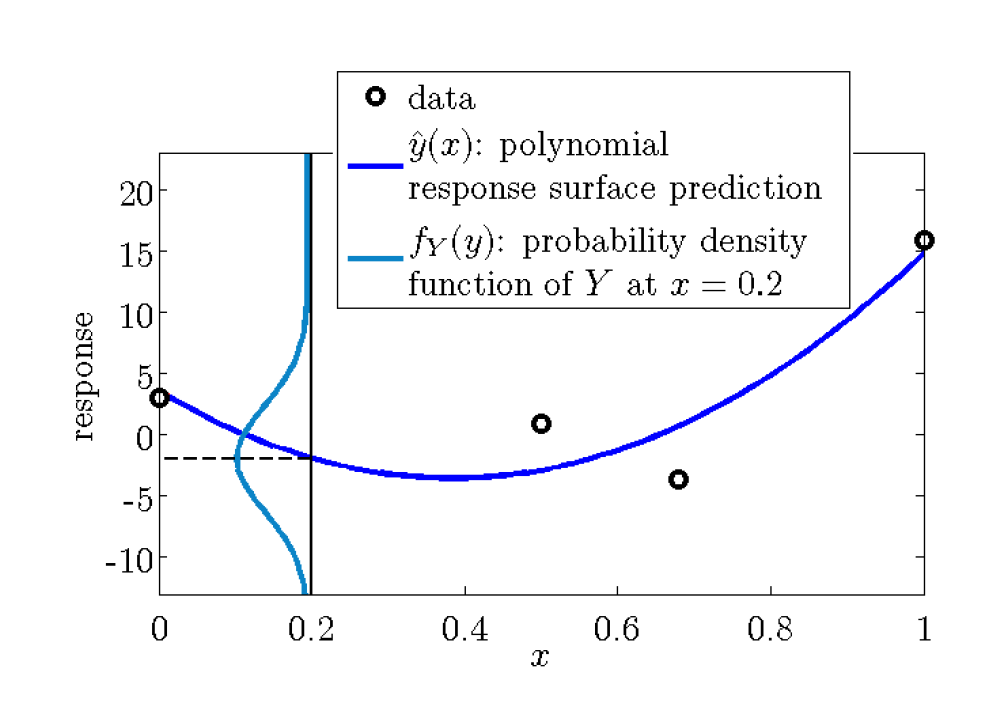


## 8.2 Gaussian Process Regression / Kriging

A Gaussian Process (GP) treats the unknown response as a stochastic function. A common representation is

$
f(\mathbf{x})\sim\mathcal{GP}(m(\mathbf{x}),k(\mathbf{x},\mathbf{x}')),
$

where $m$ is a mean function and $k$ is a covariance kernel.

GPs are particularly attractive for expensive engineering design because they can provide both

$
\mu(\mathbf{x}) = \text{predicted mean}
$

and

$
\sigma(\mathbf{x}) = \text{predictive uncertainty}.
$

That uncertainty can guide **sequential sampling**: evaluate new expensive points where the surrogate is uncertain or where improvement is promising.

**Strengths:** data-efficient, smooth, uncertainty-aware.

**Weaknesses:** computational cost increases substantially with large datasets; results depend on kernel and hyperparameter choices.


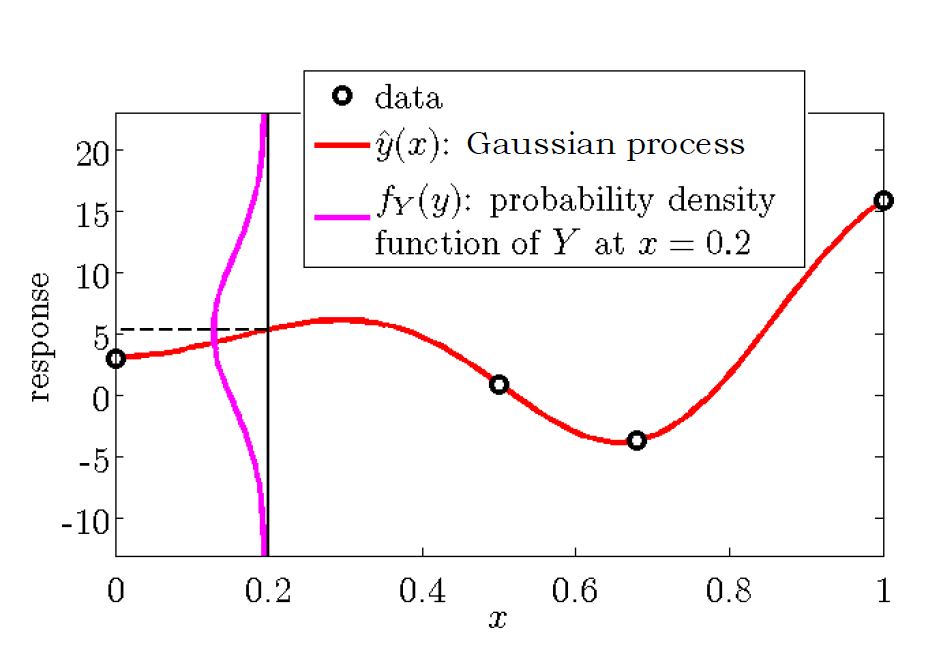


## 8.3 Radial Basis Functions (RBF)

An RBF surrogate can be expressed as

$
\hat f(\mathbf{x})
=
\sum_{i=1}^{N}w_i\phi(\|\mathbf{x}-\mathbf{x}^{(i)}\|),
$

where $\phi$ is a radial basis function.

RBFs are useful for smooth multidimensional interpolation and are common in engineering optimization.

## 8.4 Tree-based and machine-learning surrogates

Models such as Random Forests, gradient boosting, and neural networks can represent complicated nonlinear relationships.

They are often useful when:
- datasets are larger,
- responses are strongly nonlinear,
- smooth analytic derivatives are not required.

However, an optimizer can exploit irregularities or artifacts in any surrogate. High predictive accuracy alone does not eliminate the need for design-point verification.



# 9. Demonstration problem: an expensive engineering response

For illustration purposes, we will create a synthetic two-variable response and pretend that every call represents an expensive simulation.

The true function is available only so that we can evaluate how well different surrogates behave.


In [ ]:
def expensive_response(X):
    X = np.atleast_2d(X)
    x1, x2 = X[:,0], X[:,1]
    return (
        2.0
        + 0.7*(x1-0.25)**2
        + 0.45*(x2+0.15)**2
        - 1.3*np.exp(-5*((x1-0.35)**2 + (x2+0.25)**2))
        + 0.12*np.sin(5*x1)*np.cos(4*x2)
    )

bounds_demo = np.array([[-1.0, 1.0], [-1.0, 1.0]])

# 18 expensive evaluations chosen by LHS
sampler = qmc.LatinHypercube(d=2, seed=12)
X_train = qmc.scale(sampler.random(18), bounds_demo[:,0], bounds_demo[:,1])
y_train = expensive_response(X_train)

pd.DataFrame(np.c_[X_train, y_train],
             columns=["x1", "x2", "response"]).head()


,x1,x2,response
0,-0.472314,-0.549639,2.458430
1,-0.243258,-0.908810,2.502983
2,-0.594432,0.752162,2.885356
3,0.592173,-0.679453,1.802867
4,0.233743,0.460208,2.040716


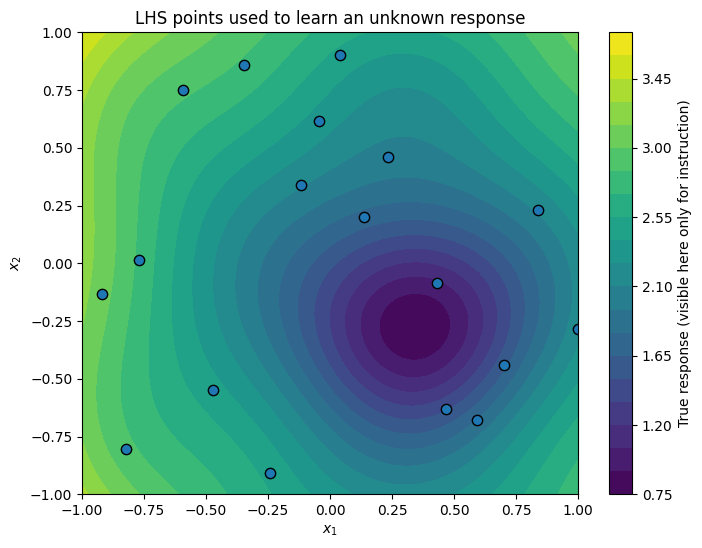

In [ ]:
# Visualize the sampled points over the true surface (for teaching only)
grid = np.linspace(-1, 1, 120)
xx, yy = np.meshgrid(grid, grid)
XY = np.c_[xx.ravel(), yy.ravel()]
zz = expensive_response(XY).reshape(xx.shape)

fig, ax = plt.subplots(figsize=(8,6))
cs = ax.contourf(xx, yy, zz, levels=25)
ax.scatter(X_train[:,0], X_train[:,1], edgecolor="black", s=55)
ax.set(xlabel="$x_1$", ylabel="$x_2$",
       title="LHS points used to learn an unknown response")
fig.colorbar(cs, ax=ax, label="True response (visible here only for instruction)")
plt.show()



# 10. Fit several surrogate models

We compare:

1. a quadratic polynomial,
2. a Random Forest,
3. a Gaussian Process.

The point is not to declare one model universally best. Instead, **surrogate selection should be evidence-based** and should consider the data regime and engineering objective.


In [ ]:
poly = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

rf = RandomForestRegressor(
    n_estimators=400, min_samples_leaf=2, random_state=42
)

kernel = ConstantKernel(1.0, (1e-2, 1e2)) * Matern(
    length_scale=[0.5, 0.5], nu=2.5
) + WhiteKernel(noise_level=1e-6, noise_level_bounds=(1e-10, 1e-2))

gp = make_pipeline(
    StandardScaler(),
    GaussianProcessRegressor(kernel=kernel, normalize_y=True,
                             n_restarts_optimizer=4, random_state=42)
)

models = {"Quadratic": poly, "Random Forest": rf, "Gaussian Process": gp}

for model in models.values():
    model.fit(X_train, y_train)



# 11. Surrogate validation

Never judge a surrogate only by its fit to the training points.

Useful measures include:

$
RMSE=
\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat y_i)^2}
$

and

$
R^2=1-\frac{\sum(y_i-\hat y_i)^2}
{\sum(y_i-\bar y)^2}.
$

When expensive evaluations are scarce, **leave-one-out cross-validation (LOOCV)** is useful: each observation is predicted by a model trained on all other observations.


In [ ]:
results = []
loo = LeaveOneOut()

for name, model in models.items():
    y_cv = cross_val_predict(model, X_train, y_train, cv=loo)
    results.append({
        "Model": name,
        "LOOCV RMSE": mean_squared_error(y_train, y_cv)**0.5,
        "LOOCV R2": r2_score(y_train, y_cv)
    })

pd.DataFrame(results).sort_values("LOOCV RMSE")


,Model,LOOCV RMSE,LOOCV R2
2,Gaussian Process,0.150664,0.923903
0,Quadratic,0.306182,0.685729
1,Random Forest,0.349681,0.590089



## Validation plots

A parity plot compares predicted and observed responses. Ideal predictions lie on the 45° line.

Residual plots are also useful. Patterns in residuals can reveal:
- missing curvature,
- heteroscedasticity,
- local regions of poor fit,
- outliers,
- or an inadequate surrogate family.


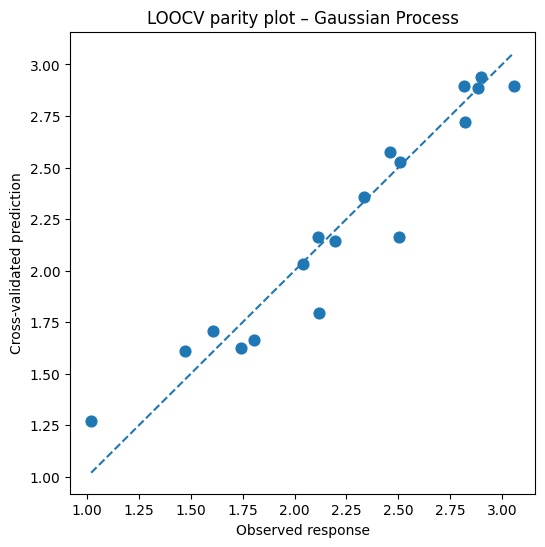

In [ ]:
best_name = min(
    results, key=lambda d: d["LOOCV RMSE"]
)["Model"]
best_model = models[best_name]

y_cv = cross_val_predict(best_model, X_train, y_train, cv=loo)

fig, ax = plt.subplots(figsize=(6,6))
ax.scatter(y_train, y_cv, s=60)
lo = min(y_train.min(), y_cv.min())
hi = max(y_train.max(), y_cv.max())
ax.plot([lo,hi],[lo,hi],"--")
ax.set(xlabel="Observed response", ylabel="Cross-validated prediction",
       title=f"LOOCV parity plot – {best_name}")
plt.show()



# 12. Surrogate-based design optimization

Once a validated surrogate is available, solve

$
\mathbf{x}_{s}^{*}
=
\arg\min_{\mathbf{x}\in\Omega}\hat f(\mathbf{x}).
$

The surrogate optimum is only a **candidate** optimum. It should be checked using the expensive original function:

$
f(\mathbf{x}_{s}^{*}).
$

If the discrepancy is too large, add the new point to the dataset, refit the surrogate, and optimize again.

This produces a sequential loop:

$
\boxed{
DOE \rightarrow
Evaluation \rightarrow
Surrogate \rightarrow
Optimization \rightarrow
Verification \rightarrow
Enrichment
}
$


In [ ]:
# Optimize each surrogate within the original bounds
opt_results = []

for name, model in models.items():
    result = differential_evolution(
        lambda x: float(model.predict(np.asarray(x).reshape(1,-1))[0]),
        bounds=[tuple(b) for b in bounds_demo],
        seed=42,
        polish=True
    )
    xstar = result.x
    pred = result.fun
    verified = expensive_response(xstar)[0]
    opt_results.append({
        "Surrogate": name,
        "x1*": xstar[0],
        "x2*": xstar[1],
        "Predicted response": pred,
        "Verified response": verified,
        "|verification error|": abs(pred-verified)
    })

pd.DataFrame(opt_results).round(4)


,Surrogate,x1*,x2*,Predicted response,Verified response,|verification error|
0,Quadratic,0.3207,-0.2607,1.5367,0.7758,0.7609
1,Random Forest,0.4337,-0.5550,1.5021,1.2491,0.2530
2,Gaussian Process,0.3812,-0.2472,0.9184,0.7850,0.1334



# 13. Sequential surrogate refinement

A one-shot DOE is not always sufficient. In **sequential design**, new expensive evaluations are selected after examining the current surrogate.

Two broad goals compete:

### Exploitation
Sample where the surrogate predicts good designs.

### Exploration
Sample where knowledge is poor or predictive uncertainty is large.

For Gaussian Processes, acquisition functions can combine these goals. Examples include:
- Expected Improvement (EI),
- Probability of Improvement (PI),
- Lower/Upper Confidence Bounds.

The general idea is:

1. construct an initial space-filling DOE;
2. fit a surrogate;
3. quantify what is promising and/or uncertain;
4. select a new expensive point;
5. update the surrogate;
6. repeat until the evaluation budget or convergence criterion is reached.

This is closely related to **Bayesian optimization** when a probabilistic surrogate and acquisition function are used.


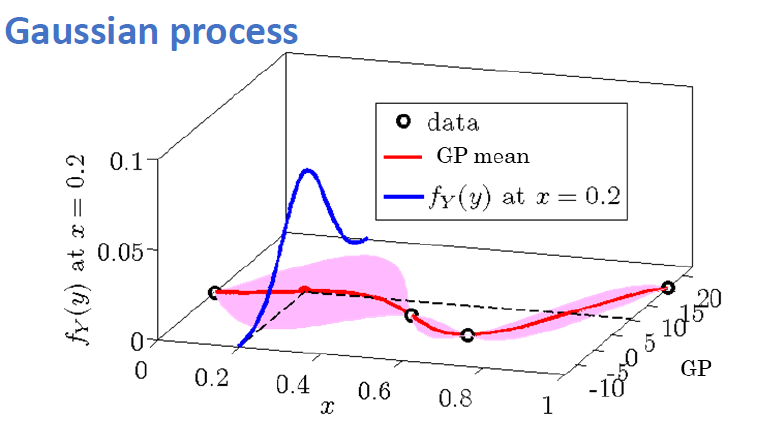

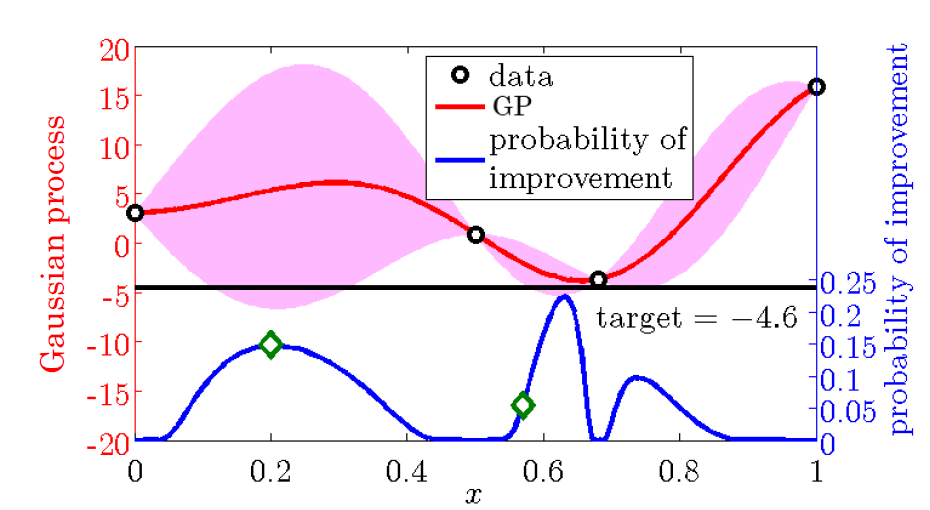


# 14. Replication, noise, and experimental uncertainty

The reference paper-helicopter exercise requires each design to be repeated several times. Replication is essential when the measured response contains random variability.

For design $i$, with $r$ repeated measurements,

$
\bar y_i=\frac{1}{r}\sum_{j=1}^{r}y_{ij}
$

and the sample variance is

$
s_i^2=
\frac{1}{r-1}\sum_{j=1}^{r}(y_{ij}-\bar y_i)^2.
$

Replicates help distinguish:

- variation caused by design variables,
- experimental noise,
- measurement error,
- uncontrolled environmental effects.

### Replication versus additional unique DOE points

With a fixed total budget, there is a tradeoff:

- more **unique designs** improve spatial coverage;
- more **replicates** improve estimation of noise.

The right balance depends on how noisy the experiment is.



# 15. Extrapolation is dangerous

A surrogate is primarily supported **inside the region represented by the DOE**.

Optimization should therefore normally respect the sampled design bounds:

$
\mathbf{x}^{L}\le\mathbf{x}\le\mathbf{x}^{U}.
$

A mathematically attractive solution outside the sampled domain is an extrapolation. It may be physically unreasonable and is not strongly supported by the data.

This is one reason the DOE and optimization domain should be defined deliberately before collecting expensive data.



# 16. Constraints in surrogate-based design

Suppose both the objective and constraints are expensive:

$$
\min_{\mathbf{x}} f(\mathbf{x})
$$

subject to

$$
g_1(\mathbf{x})\le0,\qquad g_2(\mathbf{x})\le0.
$$

Separate surrogates may be constructed:

$
\hat f(\mathbf{x}),\quad
\hat g_1(\mathbf{x}),\quad
\hat g_2(\mathbf{x}).
$

The approximate optimization becomes

$$
\min_{\mathbf{x}}\hat f(\mathbf{x})
$$

subject to

$$
\hat g_j(\mathbf{x})\le0.
$$

Near an active constraint boundary, surrogate error can incorrectly classify feasibility. Consequently, predicted optimal and near-boundary designs deserve high-fidelity verification.



# 17. Practical workflow for an engineering project

A defensible surrogate-based design study typically follows these steps:

1. **Define the design problem.** Specify objective, variables, bounds, constraints, and measurable responses.
2. **Determine the evaluation budget.** How many simulations/experiments are realistically affordable?
3. **Choose the DOE.** Use factorial designs for structured factor studies or space-filling designs such as LHS for global continuous surrogates.
4. **Run the experiment/simulation.** Record metadata, failures, and repeated observations.
5. **Preprocess carefully.** Check units, coding, missing values, and scaling.
6. **Fit candidate surrogates.** Avoid assuming a single model class is automatically best.
7. **Validate.** Use held-out points or cross-validation and inspect residuals.
8. **Optimize the surrogate.**
9. **Verify the predicted optimum using the original system.**
10. **Enrich and repeat if necessary.**
11. **Report uncertainty and limitations.**



# 18. Connection to the paper-helicopter case study

The reference lecture proposes optimizing paper-helicopter flight duration with a maximum of **15 distinct trials** and at least **4 repetitions per trial**. Listed design variables include rotor radius, rotor width, tail length, tail width, and body length.

This is an excellent example of surrogate-based experimental design because:

- the response is measured experimentally;
- several continuous geometric variables influence performance;
- exhaustive factorial testing would quickly become expensive;
- measurements contain random variation;
- a limited trial budget motivates an efficient DOE;
- the resulting surrogate can be optimized to propose a new design.

The accompanying guided assignment develops this case into a complete LHS → experiment/simulation → surrogate → validation → optimization → verification exercise.



# 19. Key takeaways

- DOE determines **where we learn** about the engineering system.
- Full factorial designs are systematic but scale poorly with dimension.
- LHS is a practical **space-filling design** for continuous variables and expensive evaluations.
- A surrogate replaces an expensive response with an inexpensive approximation.
- Surrogate accuracy must be assessed on data not used directly to fit the model.
- Optimization should remain inside the supported design domain.
- A surrogate optimum must be **verified** with the original experiment or simulation.
- Replication is necessary when experimental responses are noisy.
- Sequential enrichment can improve the surrogate where accuracy matters most.

